# Dataset mensual automático · Santa Isabel · Sentinel-2 → YOLO Segmentation

Un solo flujo desatendido: una adquisición real como máximo por mes (2016–2026), selección por visibilidad en las
cumbres, L2A preferente con respaldo histórico L1C + Cloud Score+, pseudoetiquetas NDSI sin clics y dos datasets YOLO
(`rgb` y `espectral`) con splits idénticos. Es la misma función que `python -m mensual --config configuracion.toml`.

**Requisitos:** kernel del entorno `gee` y, para consultar Earth Engine, credenciales ya creadas
(`earthengine authenticate` y `earthengine set_project <proyecto>` una vez, fuera de este cuaderno).
El flujo nunca pide autenticación dentro del bucle: sin credenciales, los meses quedan `error_reintentable`.

1. **Celda 1** – configuración (único lugar que conviene editar).
2. **Celda 2** – encuadre del AOI y de los tres sectores del núcleo sobre la escena piloto.
3. **Celda 3** – regresión sin red con la escena piloto (opcional).
4. **Celda 4** – ejecución (reanudable: repetirla continúa donde quedó).
5. **Celda 5** – resumen por mes y rutas de los dos `data.yaml`.

In [3]:
# Celda 1 · Configuración
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "mensual").is_dir() else Path.cwd() / "dataset_mensual_yolo"
sys.path.insert(0, str(RAIZ))
import mensual

CONFIG = RAIZ / "configuracion.toml"
CAMBIOS = {
    # Descomentar para una prueba corta o una ejecución reproducible:
    # "periodo__meses": ["2016-01", "2024-01"],
    # "salida__directorio": "salida_prueba",
    # "periodo__corte_utc": "2026-11-22",
    # "fuentes__modo": "solo_l2a",
    # "etiquetas__L2A__ambiguos_bloquean": False, "etiquetas__L1C__ambiguos_bloquean": False,
}
SIN_RED = False          # True: solo caché local, sin Earth Engine
EJECUTAR = True          # "botón" lógico de la celda 4

cfg = mensual.cargar_configuracion(CONFIG, **CAMBIOS)
print("Periodo", cfg["periodo"]["anio_inicio"], "–", cfg["periodo"]["anio_fin"],
      "· meses", cfg["periodo"]["meses"] or "todos", "· fuentes", cfg["fuentes"]["modo"],
      "· salida", cfg.ruta(cfg["salida"]["directorio"]))
print("AOI WGS84 [oeste, sur, este, norte]:", cfg["aoi"]["caja_wgs84"], "· núcleo:", cfg["nucleo"]["caja_wgs84"])

Periodo 2016 – 2026 · meses todos · fuentes l2a_preferente · salida C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS GEE\Selector de imágen satelital\dataset_mensual_yolo\salida
AOI WGS84 [oeste, sur, este, norte]: [-75.397, 4.773, -75.348, 4.827] · núcleo: [-75.385, 4.775, -75.348, 4.827]


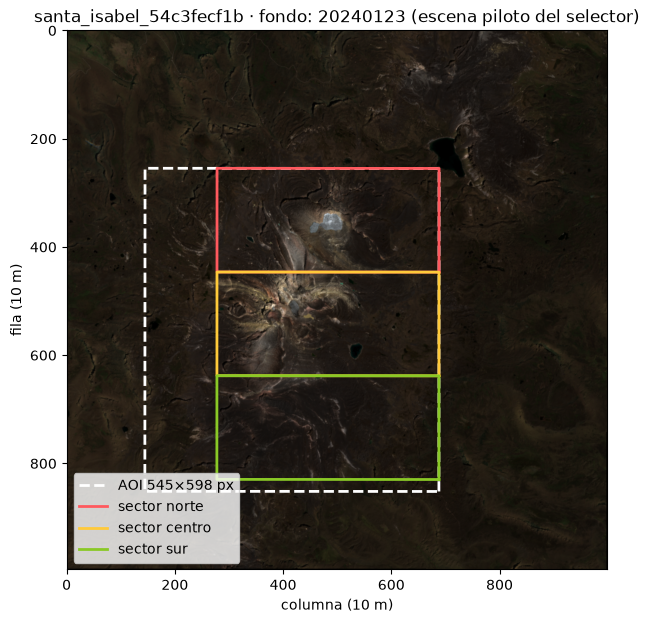

{'id_aoi': 'santa_isabel_54c3fecf1b', 'aoi_wgs84': [-75.397, 4.773, -75.348, 4.827], 'nucleo_wgs84': [-75.385, 4.775, -75.348, 4.827], 'sectores': {'norte': [-75.385, 4.809666666666667, -75.348, 4.827], 'centro': [-75.385, 4.792333333333334, -75.348, 4.809666666666667], 'sur': [-75.385, 4.775, -75.348, 4.792333333333334]}}


In [4]:
# Celda 2 · Encuadre del AOI y del núcleo de cumbres (ajustar [aoi] / [nucleo] en el TOML si no encuadran las cumbres)
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from mensual.geometria import Malla, preparar_contexto
from mensual.piloto import localizar_piloto
from mensual.utilidades import leer_json

ctx = preparar_contexto(cfg)
piloto = localizar_piloto(ctx)
fig, ax = plt.subplots(figsize=(7, 7))
if piloto is not None:  # la escena del selector puede cubrir un AOI mayor: se dibuja en su propia malla
    malla_fondo = Malla.desde_dict(leer_json(piloto / "metadata.json")["malla"])
    ax.imshow(np.asarray(Image.open(piloto / "rgb" / f"{piloto.name}.png").convert("RGB")))
    ax.set_title(f"{ctx.id_aoi} · fondo: {piloto.name[:8]} (escena piloto del selector)")
else:
    malla_fondo = ctx.malla
    ax.imshow(np.zeros((ctx.malla.alto, ctx.malla.ancho)), cmap="gray")
    ax.set_title(f"{ctx.id_aoi} · sin escena piloto local")
inv = ~malla_fondo.afin
x, y = zip(*(inv * xy for xy in ctx.geom_proj.exterior.coords))
ax.plot(x, y, color="white", lw=2, ls="--", label=f"AOI {ctx.malla.ancho}×{ctx.malla.alto} px")
colores = ["#ff595e", "#ffca3a", "#8ac926", "#1982c4", "#6a4c93"]
for (nombre, _, gp), color in zip(ctx.sectores, colores):
    x, y = zip(*(inv * xy for xy in gp.exterior.coords))
    ax.plot(x, y, color=color, lw=2, label=f"sector {nombre}")
ax.set_xlim(0, malla_fondo.ancho); ax.set_ylim(malla_fondo.alto, 0)
ax.legend(loc="lower left"); ax.set_xlabel("columna (10 m)"); ax.set_ylabel("fila (10 m)")
plt.show()
print({k: v for k, v in ctx.resumen().items() if k != "malla"})

In [5]:
# Celda 3 · Regresión sin red con la escena piloto del selector (opcional)
from mensual.piloto import imprimir_regresion, regresion_piloto

if piloto is not None:
    imprimir_regresion(regresion_piloto(piloto, cfg))
else:
    print("No hay escena piloto del selector para este AOI.")

Escena piloto: 20240123_T18NVL_20240123T152649_20240123T152651 · malla 999×996 EPSG:32618 · AOI del selector santa_isabel_6db5e66f6c
  Productos reproducidos: indices.tif ok, calidad.tif ok, soporte_png.tif ok, rgb.png ok, espectral.png ok
  Calidad {0: 2214, 1: 11472, 2: 981318} · soporte 991475 px
  Revisión humana 0001: positiva, 7 polígono(s), 2 descarte(s); ignoradas: —
  Decisión automática: ambigua · 10 componente(s) ambiguo(s): bajo_minimo=2, contacto_ocultacion=5, oscuro_sin_corroboracion=6, util_insuficiente=3
   parche  1 (aceptado_humano, 1264 px) → componente 3 ambiguo contacto_ocultacion
   parche  2 (aceptado_humano, 6 px) → componente 4 ambiguo oscuro_sin_corroboracion
   parche  3 (aceptado_humano, 11 px) → componente 5 ambiguo util_insuficiente
   parche  4 (aceptado_humano, 11 px) → componente 7 aceptado 
   parche  5 (aceptado_humano, 296 px) → componente 6 ambiguo contacto_ocultacion
   parche  6 (aceptado_humano, 91 px) → componente 8 ambiguo util_insuficiente
   

In [6]:
# Celda 4 · Ejecución (idéntica a: python -m mensual --config configuracion.toml)
if EJECUTAR:
    res = mensual.ejecutar(cfg, sin_red=SIN_RED)
else:
    print("EJECUTAR = False en la celda 1")

Ejecución 20261123T004816Z_135e75 · AOI santa_isabel_54c3fecf1b · malla 545×598 · corte 2026-11-23T00:48:16Z · 132 meses planificados ({'cerrado': 130, 'abierto': 1, 'futuro': 1}) · 132 a procesar · fuentes l2a_preferente · salida C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS GEE\Selector de imágen satelital\dataset_mensual_yolo\salida
Earth Engine listo · proyecto 'mapsapi1-203022' (credenciales locales) · earthengine-api 1.7.35
      reflectancia: 4 bloque(s)
      qa: 4 bloque(s)
      reflectancia: 4 bloque(s)
      qa: 4 bloque(s)
[  1/132] 2016-01 · L1C · etiqueta_ambigua · los candidatos visibles no producen una etiqueta automática segura
[  2/132] 2016-02 · L1C · sin_escena_viable · ninguna adquisición cumple visibilidad en AOI y cumbres
[  3/132] 2016-03 · L1C · sin_escena_viable · ninguna adquisición cumple visibilidad en AOI y cumbres
[  4/132] 2016-04 · L1C · sin_escena_viable · ninguna adquisición cumple visibilidad en AOI y cumbres
[  5/132] 2016-05 · L1C · sin_escena_vi

In [7]:
# Celda 5 · Resumen por mes y rutas de los dos datasets
import pandas as pd

meses = pd.read_csv(res["meses_csv"])
print("Estados (calendario completo):", meses["estado"].value_counts().to_dict())
print("Estado del producto:", res["estado_producto"], "· versión", res["version_dataset"])
for variante, ruta in res["yaml"].items():
    print(f"YAML {variante}: {ruta}")
columnas = ["mes", "estado", "perfil", "inventariados", "elegibles", "intentados", "clave_escena", "decision",
            "instancias", "split", "motivo"]
meses[meses["procesado_en_ejecucion"]][columnas]

Estados (calendario completo): {'sin_escena_viable': 113, 'etiqueta_ambigua': 18, 'futuro': 1}
Estado del producto: {'rgb': 'no_entrenable', 'espectral': 'no_entrenable'} · versión v0001
YAML rgb: C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS GEE\Selector de imágen satelital\dataset_mensual_yolo\salida\datasets\v0001\rgb\data.yaml
YAML espectral: C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS GEE\Selector de imágen satelital\dataset_mensual_yolo\salida\datasets\v0001\espectral\data.yaml


,mes,estado,perfil,inventariados,elegibles,intentados,clave_escena,decision,instancias,split,motivo
0,2016-01,etiqueta_ambigua,L1C,6,4,4,NaN,NaN,NaN,train,los candidatos visibles no producen una etique...
1,2016-02,sin_escena_viable,L1C,4,0,0,NaN,NaN,NaN,train,ninguna adquisición cumple visibilidad en AOI ...
2,2016-03,sin_escena_viable,L1C,2,0,0,NaN,NaN,NaN,train,ninguna adquisición cumple visibilidad en AOI ...
3,2016-04,sin_escena_viable,L1C,6,0,0,NaN,NaN,NaN,train,ninguna adquisición cumple visibilidad en AOI ...
4,2016-05,sin_escena_viable,L1C,4,0,0,NaN,NaN,NaN,train,ninguna adquisición cumple visibilidad en AOI ...
...,...,...,...,...,...,...,...,...,...,...,...
127,2026-08,etiqueta_ambigua,L2A,9,1,1,NaN,NaN,NaN,test,los candidatos visibles no producen una etique...
128,2026-09,sin_escena_viable,L2A,7,0,0,NaN,NaN,NaN,test,ninguna adquisición cumple visibilidad en AOI ...
129,2026-10,sin_escena_viable,L2A,10,0,0,NaN,NaN,NaN,test,ninguna adquisición cumple visibilidad en AOI ...
130,2026-11,sin_escena_viable,L2A,6,0,0,NaN,NaN,NaN,test,ninguna adquisición cumple visibilidad en AOI ...
